# Beyond Lexical Shortcuts: A Statistical and Robustness Assessment of Transformer Encoders for Depression Detection in Social Media

**Amir Seyed Danesh** (Corresponding Author)¹, **Amin Rezanejad**²

¹ University of Guilan, Faculty of Engineering of East Guilan, Department of Computer Engineering — seyeddanesh@guilan.ac.ir  
² University of Guilan, Faculty of Engineering, Department of Computer Engineering — aminrezanejad@msc.guilan.ac.ir

## Abstract
Automated detection of depression-related content in social media has the potential to support large-scale mental health research and screening. However, reported performance in this area may be affected by dataset shortcuts, source-related confounds, and insufficient statistical validation. This study presents a systematic evaluation of depression-related text classification using a publicly available Reddit dataset. We compare traditional TF–IDF models with frozen sentence embeddings from all-MiniLM-L6-v2 and a fully fine-tuned DistilBERT model. The evaluation combines held-out test-set metrics, bootstrap confidence intervals, paired model-comparison tests, stratified cross-validation, keyword-ablation experiments, interpretability analyses, and a limited cross-dataset assessment. On the Reddit test set, the frozen MiniLM models achieve an F1-score of 0.963 and an AUC of up to 0.992. Their advantage over TF–IDF with Logistic Regression is small and is not statistically significant after multiple-comparison correction in the cross-validation analysis (Holm-adjusted p = 0.074). Removing explicit depression-related terms reduces F1 by approximately 0.06–0.07 for the principal TF–IDF and MiniLM configurations, indicating substantial reliance on lexical cues. Feature analysis also identifies stylistic and collection-related tokens, including "quot," "com," and "twitter," that distinguish the dataset classes. A fully fine-tuned DistilBERT model achieves an F1-score of 0.980 on the original test set; after retraining with the keyword-ablated data, its F1-score decreases to 0.929. In a limited external evaluation using a second Hugging Face dataset of undocumented provenance, the Reddit-trained TF–IDF model's F1-score falls from 0.961 to 0.774. Cross-subreddit and user-level evaluations could not be completed because the primary dataset does not provide subreddit or user identifiers. Overall, the findings indicate that high in-domain scores should not be interpreted as evidence of clinical detection capability. Robustness testing, transparent statistical reporting, and careful dataset documentation are necessary before such models can be considered for practical mental health applications.

---

## About this notebook
This notebook merges two original notebooks. **All cell outputs are the stored outputs of the original runs; nothing was re-executed during merging.**

| Part | Content | Environment of the original run |
|---|---|---|
| **A** | TF-IDF baselines, frozen MiniLM-L6 encoder (ONNX Runtime) + LR/MLP heads, bootstrap CIs, McNemar, 10-fold CV + Friedman/Wilcoxon (Holm), LR-coefficient / LIME / occlusion interpretability, keyword ablation | CPU sandbox (needs local `assets/` folder: `data.csv`, `minilm.onnx`, `minilm_tok.json`) |
| **B** | End-to-end fine-tuned DistilBERT (original vs. ablated data), TF-IDF comparison, McNemar and bootstrap CIs, top features after ablation | Google Colab, Tesla T4 GPU (loads the dataset directly from Hugging Face) |

Dataset: [`hugginglearners/reddit-depression-cleaned`](https://huggingface.co/datasets/hugginglearners/reddit-depression-cleaned), binary label `is_depression`. Labels are subreddit-based, **not clinical**; results must not be used for diagnosis.

Both parts use the same cleaning (strip, drop empty, exact de-duplication → 7,650 posts), the same stratified 70/10/20 split and seed 42 (5,355 / 765 / 1,530).


# Part A — Baselines, frozen transformer encoders, interpretability and statistical tests
Dataset: `hugginglearners/reddit-depression-cleaned` (public, CC0), binary label `is_depression`.

**Pipeline**
1. Data, cleaning, stratified train/val/test split
2. Baselines: TF-IDF + Logistic Regression / Linear SVM / Complement Naive Bayes
3. Transformers (ONNX Runtime, frozen encoders): MiniLM-L6 (DistilBERT and BERT-base were dropped from this part: too slow/memory-heavy on the CPU sandbox) with Logistic Regression and MLP heads
4. Test-set evaluation (Acc / P / R / F1 / ROC-AUC, ROC curves, confusion matrices)
5. Statistical tests: bootstrap CIs, McNemar, paired bootstrap on AUC, 10-fold CV + Friedman + Wilcoxon (Holm)
6. Interpretability: LR coefficients, LIME, occlusion, keyword-ablation (shortcut) test, agreement between explainers

**Note:** PyTorch could not be installed in this sandbox (disk limits), so the encoders in Part A are *frozen* (feature extraction, no end-to-end fine-tuning). End-to-end fine-tuning of DistilBERT was run separately on a Colab GPU and is reported in Part B.

In [1]:
import sys, os, time, re, warnings, json
sys.path.insert(0, 'pk'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
import onnxruntime as ort
from tokenizers import Tokenizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from scipy import stats
SEED=42; np.random.seed(SEED); os.makedirs('out', exist_ok=True)
%matplotlib inline

## 1. Data

raw (7731, 2)
after dedup (7650, 2) {0: 3889, 1: 3761}
                count   mean    std  min   25%   50%    75%     max
is_depression                                                      
0              3889.0   14.3    7.3  1.0   8.0  13.0   20.0    42.0
1              3761.0  135.9  183.4  1.0  33.0  79.0  174.0  4239.0


5355 765 1530


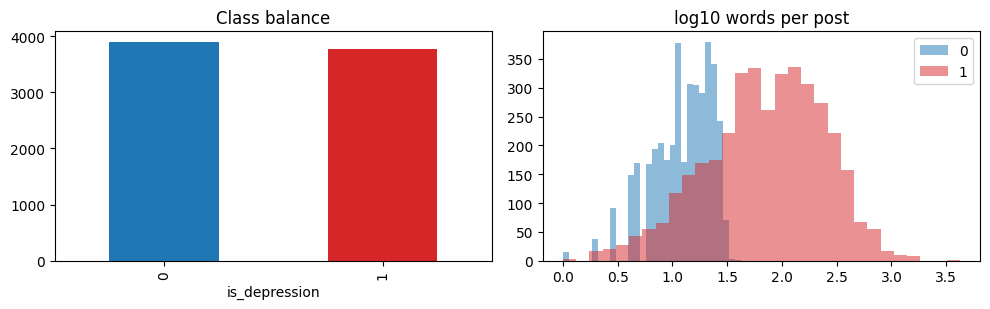

In [2]:
df = pd.read_csv('assets/data.csv').dropna()
df['clean_text'] = df.clean_text.astype(str).str.strip()
print('raw', df.shape)
df = df[df.clean_text.str.len()>0].drop_duplicates('clean_text').reset_index(drop=True)
print('after dedup', df.shape, df.is_depression.value_counts().to_dict())
df['n_words'] = df.clean_text.str.split().str.len()
print(df.groupby('is_depression').n_words.describe().round(1))
X = df.clean_text.values; y = df.is_depression.values
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.3, stratify=y, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=2/3, stratify=y[i_tmp], random_state=SEED)
print(len(i_tr), len(i_va), len(i_te))
fig,ax=plt.subplots(1,2,figsize=(10,3.2))
df.is_depression.value_counts().sort_index().plot.bar(ax=ax[0],color=['tab:blue','tab:red']); ax[0].set_title('Class balance')
for k,c in [(0,'tab:blue'),(1,'tab:red')]: ax[1].hist(np.log10(df[df.is_depression==k].n_words),bins=30,alpha=.5,color=c,label=str(k))
ax[1].set_title('log10 words per post'); ax[1].legend(); plt.tight_layout(); plt.savefig('out/eda.png',dpi=130); plt.show()

## 2. Baselines (TF-IDF)

In [3]:
def metrics(yt, yp, ps):
    return dict(Accuracy=accuracy_score(yt,yp), Precision=precision_score(yt,yp), Recall=recall_score(yt,yp),
                F1=f1_score(yt,yp), AUC=roc_auc_score(yt,ps))
tfidf = lambda: TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True, min_df=2, max_features=200000)
vec = tfidf().fit(X[i_tr]); Xtf = vec.transform(X)
RES = {}   # name -> dict(pred, score)
def tune_fit(make, grid, Xf):
    best=None
    for g in grid:
        m=make(g).fit(Xf[i_tr], y[i_tr]); s=m.decision_function(Xf[i_va]) if hasattr(m,'decision_function') else m.predict_proba(Xf[i_va])[:,1]
        a=roc_auc_score(y[i_va], s)
        if best is None or a>best[0]: best=(a,g,m)
    return best
for name, make, grid in [
    ('TFIDF+LR', lambda c: LogisticRegression(C=c,max_iter=2000), [0.1,1,3,10,30,100]),
    ('TFIDF+LinearSVM', lambda c: LinearSVC(C=c), [0.03,0.1,0.3,1,3]),
    ('TFIDF+CompNB', lambda a: ComplementNB(alpha=a), [0.03,0.1,0.3,1])]:
    a,g,m = tune_fit(make, grid, Xtf)
    s = m.decision_function(Xtf[i_te]) if hasattr(m,'decision_function') else m.predict_proba(Xtf[i_te])[:,1]
    RES[name]=dict(pred=m.predict(Xtf[i_te]), score=s, model=m, param=g)
    print(name, 'best param', g, 'val AUC %.4f'%a)
lr_tfidf = RES['TFIDF+LR']['model']

TFIDF+LR best param 30 val AUC 0.9950


TFIDF+LinearSVM best param 0.3 val AUC 0.9950
TFIDF+CompNB best param 0.3 val AUC 0.9907


## 3. Transformer encoders (frozen, ONNX Runtime)
Mean-pooled last-layer token states and the [CLS] state are extracted (max 128 tokens) and cached. Heads are trained on the features; hyper-parameters are selected on the validation set.

In [4]:
class Encoder:
    def __init__(self, tag, maxlen=128):
        so = ort.SessionOptions(); so.intra_op_num_threads = 2
        self.s = ort.InferenceSession(f'assets/{tag}.onnx', so, providers=['CPUExecutionProvider'])
        self.names = [i.name for i in self.s.get_inputs()]
        self.tok = Tokenizer.from_file(f'assets/{tag}_tok.json'); self.maxlen = maxlen
        self.tok.enable_truncation(maxlen); self.tok.enable_padding()
    def __call__(self, texts, bs=4):
        out=[]; order=np.argsort([len(t) for t in texts]); texts=[texts[i] for i in order]
        for b in range(0,len(texts),bs):
            enc=self.tok.encode_batch(texts[b:b+bs])
            ids=np.array([e.ids for e in enc],dtype=np.int64); am=np.array([e.attention_mask for e in enc],dtype=np.int64)
            feed={'input_ids':ids,'attention_mask':am}
            if 'token_type_ids' in self.names: feed['token_type_ids']=np.zeros_like(ids)
            h=self.s.run(None,feed)[0]; m=am[...,None]
            out.append(np.concatenate([(h*m).sum(1)/m.sum(1), h[:,0]],1))
        E=np.concatenate(out); R=np.empty_like(E); R[order]=E; return R
ENC = {'MiniLM-L6':'minilm'}
EMB = {}
for nm,tag in ENC.items():
    f=f'out/emb_{tag}.npy'
    if os.path.exists(f): EMB[nm]=np.load(f)
    else:
        t=time.time(); EMB[nm]=Encoder(tag)(list(X)); np.save(f,EMB[nm]); print(nm,'embedded in %.0fs'%(time.time()-t))
    print(nm, EMB[nm].shape)

MiniLM-L6 (7650, 768)


In [5]:
from sklearn.preprocessing import StandardScaler
D = {}  # dim per encoder
for nm in ENC:
    d = EMB[nm].shape[1]//2; D[nm]=d
    Z = StandardScaler().fit(EMB[nm][i_tr][:, :d]).transform(EMB[nm][:, :d])   # mean-pooled features
    for head, make, grid in [
        ('LR', lambda c: LogisticRegression(C=c,max_iter=3000), [0.001,0.003,0.01,0.03,0.1,1]),
        ('MLP', lambda a: MLPClassifier((256,),alpha=a,early_stopping=True,max_iter=300,random_state=SEED), [1e-2,1e-1,1])]:
        a,g,m = tune_fit(make, grid, Z)
        key=f'{nm}+{head}'
        s = m.decision_function(Z[i_te]) if head=='LR' else m.predict_proba(Z[i_te])[:,1]
        RES[key]=dict(pred=m.predict(Z[i_te]), score=s, model=m, param=g)
        print(key,'best param',g,'val AUC %.4f'%a)
    EMB[nm+'_Z']=Z

MiniLM-L6+LR best param 0.03 val AUC 0.9926


MiniLM-L6+MLP best param 0.01 val AUC 0.9955


## 4. Test-set results

,Accuracy,Precision,Recall,F1,AUC
MiniLM-L6+MLP,0.9634,0.9690,0.9561,0.9625,0.9919
MiniLM-L6+LR,0.9634,0.9690,0.9561,0.9625,0.9908
TFIDF+LinearSVM,0.9627,0.9847,0.9388,0.9612,0.9898
TFIDF+LR,0.9588,0.9778,0.9375,0.9572,0.9901
TFIDF+CompNB,0.8758,0.8061,0.9840,0.8862,0.9882


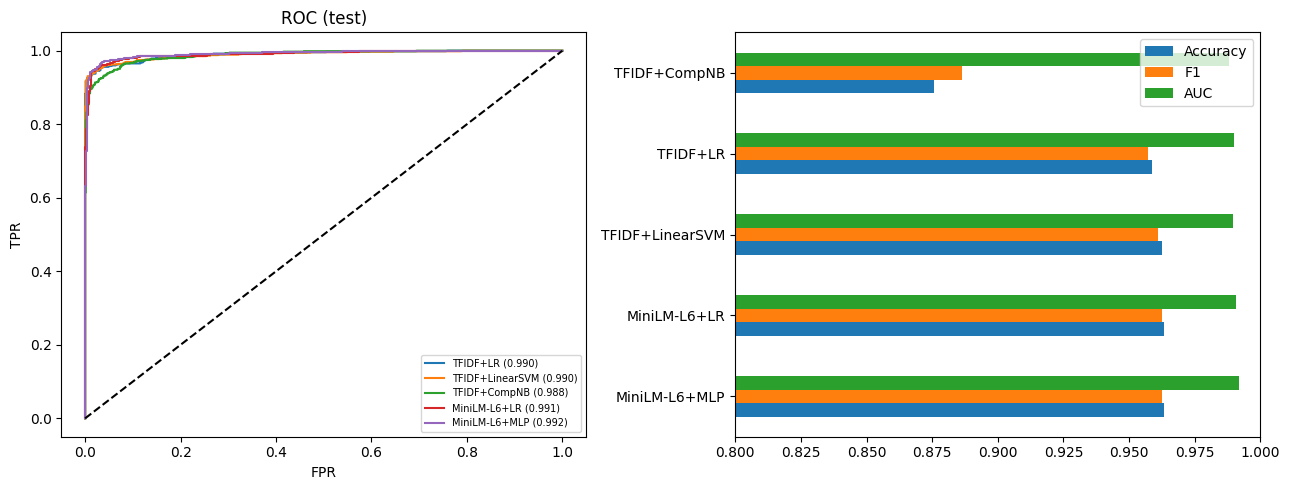

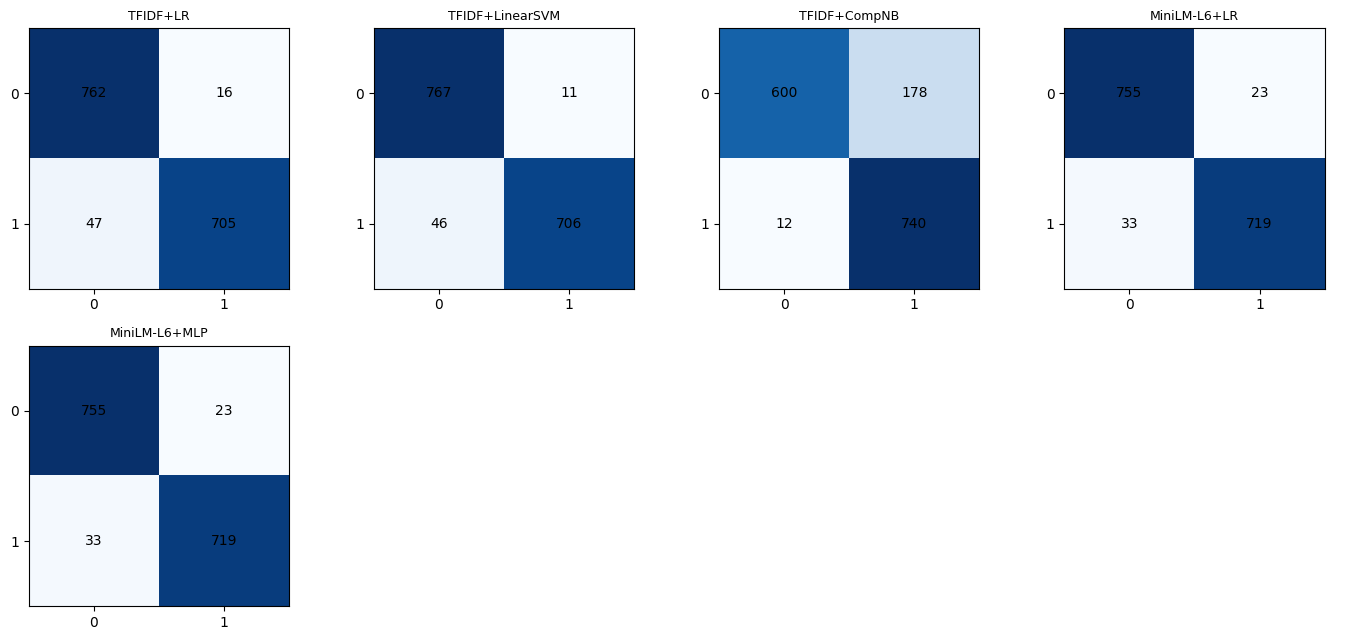

In [6]:
yt = y[i_te]
tab = pd.DataFrame({k: metrics(yt, v['pred'], v['score']) for k,v in RES.items()}).T.round(4)
tab = tab.sort_values('F1', ascending=False); tab.to_csv('out/results.csv'); display(tab)
fig,ax=plt.subplots(1,2,figsize=(13,5))
for k,v in RES.items():
    fp,tp,_=roc_curve(yt,v['score']); ax[0].plot(fp,tp,label=f"{k} ({roc_auc_score(yt,v['score']):.3f})")
ax[0].plot([0,1],[0,1],'k--'); ax[0].legend(fontsize=7); ax[0].set_title('ROC (test)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR')
tab[['Accuracy','F1','AUC']].plot.barh(ax=ax[1]); ax[1].set_xlim(.8,1); plt.tight_layout(); plt.savefig('out/roc.png',dpi=130); plt.show()
names=list(RES); fig,ax=plt.subplots(2,4,figsize=(14,6.5))
for a,k in zip(ax.ravel(),names):
    cm=confusion_matrix(yt,RES[k]['pred']); a.imshow(cm,cmap='Blues'); a.set_title(k,fontsize=9)
    for i in range(2):
        for j in range(2): a.text(j,i,cm[i,j],ha='center',va='center')
    a.set_xticks([0,1]); a.set_yticks([0,1])
for a in ax.ravel()[len(names):]: a.axis('off')
plt.tight_layout(); plt.savefig('out/cm.png',dpi=130); plt.show()

## 5. Statistical tests
**5a. Bootstrap 95% CIs** (2000 resamples of the test set).  
**5b. McNemar test** (exact binomial) on paired errors vs. the best baseline.  
**5c. Paired bootstrap test** for the AUC difference.  
**5d. 10-fold cross-validation on all data** + Friedman test + pairwise Wilcoxon signed-rank (Holm-corrected).

In [7]:
rng=np.random.default_rng(SEED); B=2000; n=len(yt)
bi = rng.integers(0,n,(B,n))
def boot(fn): return np.array([fn(b) for b in bi])
ci={}
for k,v in RES.items():
    f1s=boot(lambda b: f1_score(yt[b],v['pred'][b])); aucs=boot(lambda b: roc_auc_score(yt[b],v['score'][b]))
    ci[k]=dict(F1=f"{f1_score(yt,v['pred']):.4f} [{np.percentile(f1s,2.5):.4f}, {np.percentile(f1s,97.5):.4f}]",
               AUC=f"{roc_auc_score(yt,v['score']):.4f} [{np.percentile(aucs,2.5):.4f}, {np.percentile(aucs,97.5):.4f}]")
ci=pd.DataFrame(ci).T; ci.to_csv('out/bootstrap_ci.csv'); display(ci)

,F1,AUC
TFIDF+LR,"0.9572 [0.9466, 0.9676]","0.9901 [0.9858, 0.9939]"
TFIDF+LinearSVM,"0.9612 [0.9512, 0.9714]","0.9898 [0.9852, 0.9938]"
TFIDF+CompNB,"0.8862 [0.8689, 0.9014]","0.9882 [0.9839, 0.9918]"
MiniLM-L6+LR,"0.9625 [0.9521, 0.9719]","0.9908 [0.9865, 0.9944]"
MiniLM-L6+MLP,"0.9625 [0.9521, 0.9721]","0.9919 [0.9879, 0.9952]"


In [8]:
from scipy.stats import binomtest
base='TFIDF+LR'
rows=[]
for k in RES:
    if k==base: continue
    ca=RES[base]['pred']==yt; cb=RES[k]['pred']==yt
    b01=int((ca&~cb).sum()); b10=int((~ca&cb).sum())      # base right/other wrong ; base wrong/other right
    p=binomtest(b01,b01+b10,0.5).pvalue if b01+b10>0 else 1.0
    dA=np.array([roc_auc_score(yt[b],RES[k]['score'][b])-roc_auc_score(yt[b],RES[base]['score'][b]) for b in bi])
    d0=roc_auc_score(yt,RES[k]['score'])-roc_auc_score(yt,RES[base]['score'])
    pb=min(1,2*min((dA<=0).mean(),(dA>=0).mean()))
    rows.append(dict(model=k, base_right_other_wrong=b01, base_wrong_other_right=b10, McNemar_p=p,
                     dAUC=d0, dAUC_CI=f"[{np.percentile(dA,2.5):.4f}, {np.percentile(dA,97.5):.4f}]", boot_p=pb))
mc=pd.DataFrame(rows).set_index('model'); 
from statsmodels.stats.multitest import multipletests
mc['McNemar_p_holm']=multipletests(mc.McNemar_p,method='holm')[1] if len(mc)>1 else mc.McNemar_p
mc['boot_p_holm']=multipletests(mc.boot_p,method='holm')[1]
mc.round(4).to_csv('out/pairwise_vs_baseline.csv'); display(mc.round(4))

,base_right_other_wrong,base_wrong_other_right,McNemar_p,dAUC,dAUC_CI,boot_p,McNemar_p_holm,boot_p_holm
model,,,,,,,,
TFIDF+LinearSVM,1,7,0.0703,-0.0003,"[-0.0009, 0.0003]",0.354,0.2109,1.00
TFIDF+CompNB,165,38,0.0000,-0.0020,"[-0.0054, 0.0016]",0.245,0.0000,0.98
MiniLM-L6+LR,30,37,0.4638,0.0006,"[-0.0031, 0.0043]",0.801,0.9276,1.00
MiniLM-L6+MLP,31,38,0.4704,0.0018,"[-0.0022, 0.0057]",0.399,0.9276,1.00


In [9]:
skf=StratifiedKFold(10,shuffle=True,random_state=SEED)
cv_models={'TFIDF+LR':('tfidf',lambda: LogisticRegression(C=RES['TFIDF+LR']['param'],max_iter=2000)),
 'TFIDF+LinearSVM':('tfidf',lambda: LinearSVC(C=RES['TFIDF+LinearSVM']['param'])),
 'TFIDF+CompNB':('tfidf',lambda: ComplementNB(alpha=RES['TFIDF+CompNB']['param']))}
for nm in ENC:
    cv_models[nm+'+LR']=(nm,lambda nm=nm: LogisticRegression(C=RES[nm+'+LR']['param'],max_iter=3000))
    cv_models[nm+'+MLP']=(nm,lambda nm=nm: MLPClassifier((256,),alpha=RES[nm+'+MLP']['param'],early_stopping=True,max_iter=300,random_state=SEED))
cvF1={k:[] for k in cv_models}; cvAUC={k:[] for k in cv_models}
for tr,te in skf.split(X,y):
    v=tfidf().fit(X[tr]); Xa,Xb=v.transform(X[tr]),v.transform(X[te])
    for k,(src,mk) in cv_models.items():
        if src=='tfidf': A,Bm=Xa,Xb
        else:
            d=D[src]; sc=StandardScaler().fit(EMB[src][tr][:,:d]); A,Bm=sc.transform(EMB[src][tr][:,:d]),sc.transform(EMB[src][te][:,:d])
        m=mk().fit(A,y[tr]); s=m.decision_function(Bm) if hasattr(m,'decision_function') else m.predict_proba(Bm)[:,1]
        cvF1[k].append(f1_score(y[te],m.predict(Bm))); cvAUC[k].append(roc_auc_score(y[te],s))
cvF1=pd.DataFrame(cvF1); cvAUC=pd.DataFrame(cvAUC)
summ=pd.DataFrame({'F1 mean':cvF1.mean(),'F1 sd':cvF1.std(),'AUC mean':cvAUC.mean(),'AUC sd':cvAUC.std()}).round(4).sort_values('F1 mean',ascending=False)
summ.to_csv('out/cv_summary.csv'); display(summ)
fr=stats.friedmanchisquare(*[cvF1[k] for k in cvF1]); print('Friedman on F1 (10 folds, %d models): chi2=%.2f p=%.3g'%(cvF1.shape[1],fr.statistic,fr.pvalue))
fr2=stats.friedmanchisquare(*[cvAUC[k] for k in cvAUC]); print('Friedman on AUC: chi2=%.2f p=%.3g'%(fr2.statistic,fr2.pvalue))

,F1 mean,F1 sd,AUC mean,AUC sd
MiniLM-L6+MLP,0.9697,0.0069,0.9936,0.0022
MiniLM-L6+LR,0.9664,0.0069,0.9924,0.0022
TFIDF+LR,0.9656,0.0048,0.9922,0.0018
TFIDF+LinearSVM,0.9648,0.0048,0.9922,0.0020
TFIDF+CompNB,0.8967,0.0104,0.9886,0.0032


Friedman on F1 (10 folds, 5 models): chi2=25.76 p=3.54e-05
Friedman on AUC: chi2=21.12 p=0.0003


best CV model: MiniLM-L6+MLP


,dF1,wilcoxon_p,NB_corrected_t_p,wilcoxon_p_holm,NB_p_holm
vs,,,,,
TFIDF+LR,0.0041,0.0488,0.1487,0.0742,0.2366
TFIDF+LinearSVM,0.0049,0.0371,0.1183,0.0742,0.2366
TFIDF+CompNB,0.0730,0.0020,0.0000,0.0078,0.0000
MiniLM-L6+LR,0.0033,0.0039,0.0063,0.0117,0.0188


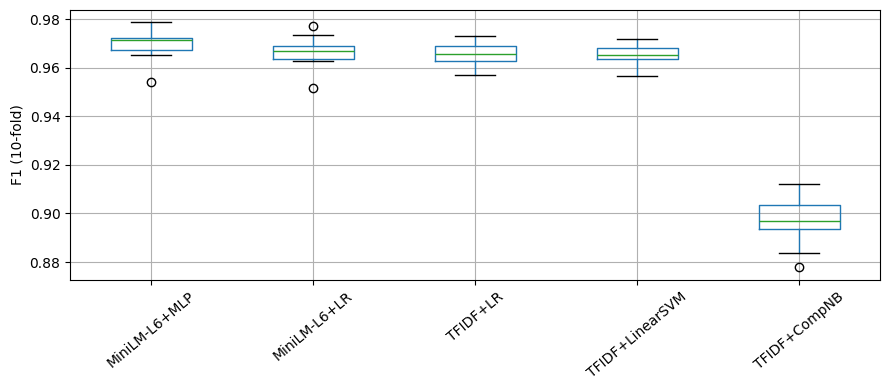

In [10]:
best_cv=summ.index[0]; print('best CV model:',best_cv)
rows=[]
for k in cvF1:
    if k==best_cv: continue
    w=stats.wilcoxon(cvF1[best_cv],cvF1[k]); d=cvF1[best_cv]-cvF1[k]
    # Nadeau-Bengio corrected resampled t-test (test/train ratio 1/9)
    t=d.mean()/np.sqrt((1/10+1/9)*d.var(ddof=1)); pt=2*stats.t.sf(abs(t),9)
    rows.append(dict(vs=k, dF1=d.mean(), wilcoxon_p=w.pvalue, NB_corrected_t_p=pt))
wt=pd.DataFrame(rows).set_index('vs'); wt['wilcoxon_p_holm']=multipletests(wt.wilcoxon_p,method='holm')[1]; wt['NB_p_holm']=multipletests(wt.NB_corrected_t_p,method='holm')[1]
wt.round(4).to_csv('out/cv_pairwise.csv'); display(wt.round(4))
plt.figure(figsize=(9,4)); cvF1[summ.index].boxplot(rot=40); plt.ylabel('F1 (10-fold)'); plt.tight_layout(); plt.savefig('out/cv_box.png',dpi=130); plt.show()

## 6. Interpretability
### 6a. Global: Logistic Regression coefficients (TF-IDF)

,depressed,coef_d,non_depressed,coef_n
0,depression,39.82,quot,-4.59
1,anxiety,12.41,sad,-4.29
2,and,12.07,com,-4.23
3,pression,8.98,oh,-3.99
4,life,8.67,ugh,-3.91
5,myself,8.00,sleep,-3.70
6,of,7.67,miss,-3.49
7,just,7.22,have to,-3.49
8,or,7.21,twitter,-3.26
9,feel,7.01,morning,-3.13


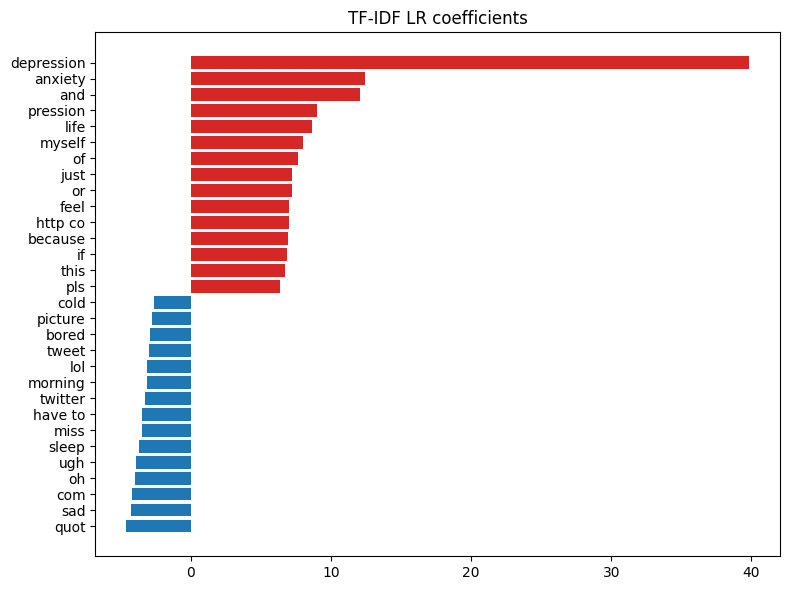

In [11]:
fn=np.array(vec.get_feature_names_out()); co=lr_tfidf.coef_[0]; o=np.argsort(co)
top=pd.DataFrame({'depressed':fn[o[::-1][:20]],'coef_d':co[o[::-1][:20]].round(2),'non_depressed':fn[o[:20]],'coef_n':co[o[:20]].round(2)}); display(top); top.to_csv('out/lr_top.csv',index=False)
fig,ax=plt.subplots(figsize=(8,6)); sel=np.r_[o[:15],o[-15:]]; ax.barh(fn[sel],co[sel],color=np.where(co[sel]>0,'tab:red','tab:blue')); ax.set_title('TF-IDF LR coefficients'); plt.tight_layout(); plt.savefig('out/lr_coef.png',dpi=130); plt.show()

### 6b. Local: LIME and occlusion for the best transformer model (MiniLM-L6 + LR)
The classifier is wrapped as text → P(depressed); the encoder is run on every perturbed text.

In [12]:
from lime.lime_text import LimeTextExplainer
tm='MiniLM-L6'; enc_b=Encoder('minilm'); d=D[tm]
scB=StandardScaler().fit(EMB[tm][i_tr][:,:d]); clfB=RES[tm+'+LR']['model']
def p_bert(texts):
    texts=[t if t.strip() else 'empty' for t in texts]
    return clfB.predict_proba(scB.transform(enc_b(list(texts))[:,:d]))
p_tfidf=lambda texts: lr_tfidf.predict_proba(vec.transform(texts))
# sanity check
print(np.abs(p_bert(list(X[i_te[:8]]))[:,1] - clfB.predict_proba(EMB[tm+'_Z'][i_te[:8]])[:,1]).max())
rs=np.random.default_rng(1); short=[i for i in i_te if 8<=df.n_words[i]<=60]
sample=rs.choice(short,12,replace=False)
expl=LimeTextExplainer(class_names=['non-dep','dep'],random_state=SEED)
lime_b={}; lime_t={}
t=time.time()
for i in sample:
    lime_b[i]=dict(expl.explain_instance(X[i],p_bert,num_features=10,num_samples=300).as_list())
    lime_t[i]=dict(expl.explain_instance(X[i],p_tfidf,num_features=10,num_samples=300).as_list())
print('LIME %.0fs'%(time.time()-t))
for i in sample[:4]:
    print('\nTEXT:',X[i][:300],'| label',y[i],'| P_bert=%.2f'%p_bert([X[i]])[0,1])
    print(' BERT LIME :',{k:round(v,2) for k,v in sorted(lime_b[i].items(),key=lambda z:-abs(z[1]))[:6]})
    print(' TFIDF LIME:',{k:round(v,2) for k,v in sorted(lime_t[i].items(),key=lambda z:-abs(z[1]))[:6]})

0.0


LIME 45s

TEXT: landed funny on my foot this morning while jumping down the stair and i twisted it quite sore now | label 0 | P_bert=0.01
 BERT LIME : {'sore': -0.01, 'funny': -0.01, 'twisted': -0.01, 'stair': 0.0, 'the': 0.0, 'down': 0.0}
 TFIDF LIME: {'morning': -0.05, 'and': 0.04, 'this': 0.02, 'twisted': -0.02, 'sore': -0.02, 'stair': -0.02}

TEXT: quand vous comprendrait que tre gros ne viens pa du fait de mal manger mais de plein d autre facteurs la g n tique le tca le hormone le trouble mentaux la d pression l anxi t ect l o pourrais avancer | label 1 | P_bert=1.00
 BERT LIME : {'mais': 0.02, 'le': 0.02, 'tca': -0.02, 'autre': 0.02, 'pa': 0.02, 'hormone': 0.01}
 TFIDF LIME: {'pression': 0.23, 'de': 0.21, 'la': 0.16, 'le': 0.11, 'du': 0.06, 'autre': 0.04}

TEXT: dynoisthename haha you better watch those two they might actually kill each other | label 0 | P_bert=0.01
 BERT LIME : {'haha': -0.06, 'dynoisthename': -0.03, 'each': 0.02, 'better': -0.02, 'they': 0.02, 'other': 0.02}
 T

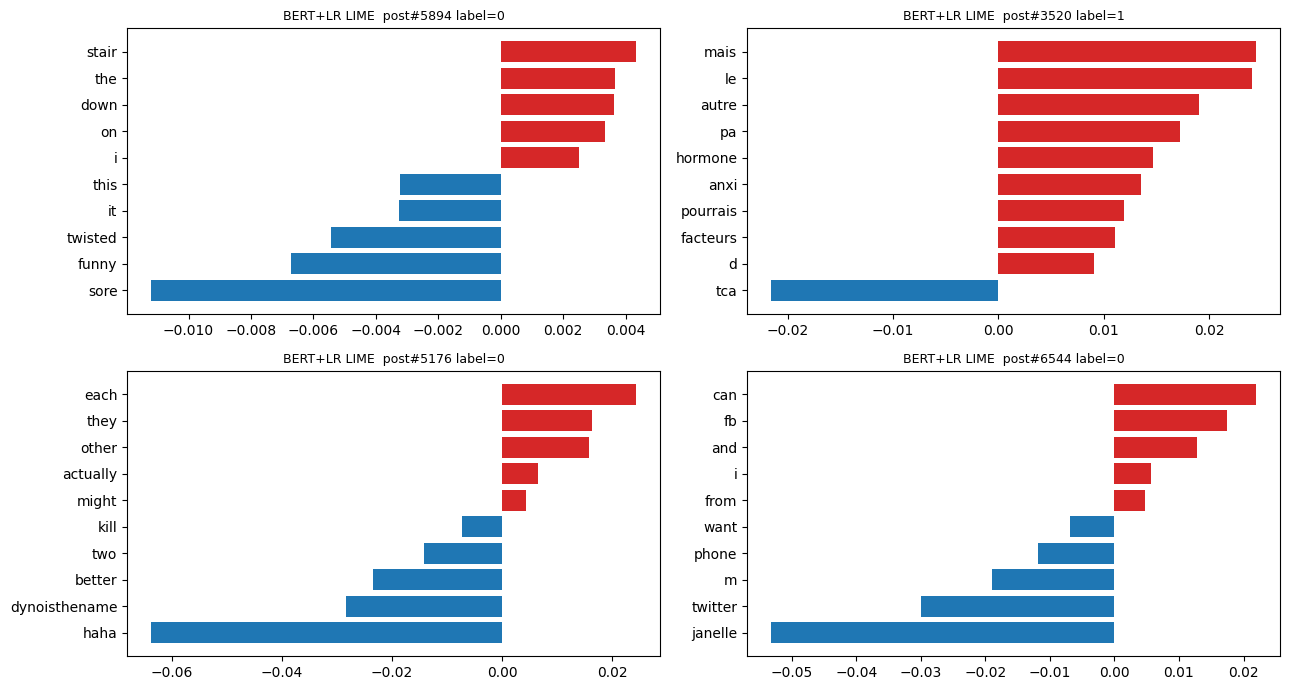

In [13]:
fig,ax=plt.subplots(2,2,figsize=(13,7))
for a,i in zip(ax.ravel(),sample[:4]):
    w=sorted(lime_b[i].items(),key=lambda z:z[1]); a.barh([k for k,_ in w],[v for _,v in w],color=['tab:red' if v>0 else 'tab:blue' for _,v in w]); a.set_title(f'BERT+LR LIME  post#{i} label={y[i]}',fontsize=9)
plt.tight_layout(); plt.savefig('out/lime.png',dpi=130); plt.show()

In [14]:
# Occlusion (leave-one-word-out) on 40 test posts of <=40 words
def occlusion(text, f):
    w=text.split(); base=f([text])[0,1]; vs=[' '.join(w[:j]+w[j+1:]) for j in range(len(w))]
    return w, base, base-f(vs)[:,1]     # positive = word pushes toward depressed
occ_idx=rs.choice([i for i in i_te if 5<=df.n_words[i]<=40],40,replace=False)
t=time.time(); OC=[]
for i in occ_idx:
    w,b,s=occlusion(X[i],p_bert); OC+= list(zip(w,s))
print('occlusion %.0fs'%(time.time()-t))
oc=pd.DataFrame(OC,columns=['word','delta']).groupby('word').delta.agg(['mean','count']); oc=oc[oc['count']>=3].sort_values('mean')
oc_top=pd.concat([oc.tail(12)[::-1],oc.head(12)]).round(3); display(oc_top); oc_top.to_csv('out/occlusion_top.csv')
i=occ_idx[0]; w,b,s=occlusion(X[i],p_bert)
import html
sc=np.clip(s/(np.abs(s).max()+1e-9),-1,1)
span=''.join(f'<span style="background:rgba({255 if v>0 else 0},0,{0 if v>0 else 255},{abs(v):.2f});padding:1px">{html.escape(t)}</span> ' for t,v in zip(w,sc))
from IPython.display import HTML; display(HTML(f'<p>label={y[i]} P(dep)={b:.2f}</p>'+span))

occlusion 7s


,mean,count
word,,
depression,0.853,5
want,0.045,4
i,0.030,29
for,0.023,6
just,0.019,11
and,0.016,5
yet,0.015,3
me,0.014,8
time,0.013,4


### 6c. Do the explainers agree? (Spearman rank correlation)
For each explained post, compare word attributions of BERT-LIME and TF-IDF-LIME, and TF-IDF-LIME with the global LR coefficients.

In [15]:
cors=[]
for i in sample:
    common=[k for k in lime_b[i] if k in lime_t[i]]
    if len(common)>=4: cors.append(stats.spearmanr([lime_b[i][k] for k in common],[lime_t[i][k] for k in common])[0])
cors=np.array(cors); print('BERT-LIME vs TFIDF-LIME: mean rho=%.2f (n=%d posts)'%(np.nanmean(cors),len(cors)))
vocab={w:j for j,w in enumerate(fn)}; g=[]
for i in sample:
    ks=[k for k in lime_t[i] if k in vocab]
    if len(ks)>=4: g.append(stats.spearmanr([lime_t[i][k] for k in ks],[co[vocab[k]] for k in ks])[0])
print('TFIDF-LIME vs LR coef: mean rho=%.2f'%np.nanmean(g))
# word overlap between BERT-occlusion and LR coef for words with >=3 occurrences
com=[w for w in oc.index if w in vocab]; r=stats.spearmanr(oc.loc[com,'mean'],[co[vocab[w]] for w in com]); print('occlusion(BERT) vs LR coef: rho=%.2f p=%.3g n=%d'%(r[0],r[1],len(com)))

BERT-LIME vs TFIDF-LIME: mean rho=0.53 (n=12 posts)
TFIDF-LIME vs LR coef: mean rho=0.92
occlusion(BERT) vs LR coef: rho=0.30 p=0.0571 n=41


### 6d. Shortcut / artefact test
The explanations show that the word *depression* (and tweet-style tokens) carry a lot of weight. We test the effect by removing these words from the **test** posts (models are not retrained) and by retraining without them.

In [16]:
kw=re.compile(r'\b(depression|depressed|depress\w*)\b'); strip=lambda t: re.sub(r'\s+',' ',kw.sub(' ',t)).strip() or 'empty'
Xte_s=[strip(t) for t in X[i_te]]
print('test posts containing the keyword: %.1f%% (dep) / %.1f%% (non-dep)'%tuple(100*np.mean([bool(kw.search(t)) for t in X[i_te][yt==k]]) for k in (1,0)))
Zs=scB.transform(Encoder('minilm')(Xte_s)[:,:d])
abl={'TFIDF+LR':(lr_tfidf.predict(vec.transform(Xte_s)),lr_tfidf.decision_function(vec.transform(Xte_s))),
     'MiniLM-L6+LR':(clfB.predict(Zs),clfB.decision_function(Zs))}
rows=[]
for k,(p,s) in abl.items():
    a=metrics(yt,RES[k]['pred'],RES[k]['score']); b=metrics(yt,p,s)
    rows.append(dict(model=k,F1_orig=a['F1'],F1_no_keyword=b['F1'],AUC_orig=a['AUC'],AUC_no_keyword=b['AUC']))
ab=pd.DataFrame(rows).set_index('model').round(4); display(ab); ab.to_csv('out/ablation.csv')
# significance of the drop: McNemar between original and ablated predictions
for k,(p,s) in abl.items():
    c0=RES[k]['pred']==yt; c1=p==yt; b01=int((c0&~c1).sum()); b10=int((~c0&c1).sum())
    print(k,'orig-right/ablated-wrong=%d, orig-wrong/ablated-right=%d, McNemar p=%.3g'%(b01,b10,binomtest(b01,b01+b10,.5).pvalue))

test posts containing the keyword: 38.7% (dep) / 0.5% (non-dep)


,F1_orig,F1_no_keyword,AUC_orig,AUC_no_keyword
model,,,,
TFIDF+LR,0.9572,0.8845,0.9901,0.9592
MiniLM-L6+LR,0.9625,0.9012,0.9908,0.9653


TFIDF+LR orig-right/ablated-wrong=96, orig-wrong/ablated-right=0, McNemar p=2.52e-29
MiniLM-L6+LR orig-right/ablated-wrong=85, orig-wrong/ablated-right=2, McNemar p=4.95e-23


In [17]:
# retrain TF-IDF LR on keyword-free text
Xs_all=np.array([strip(t) for t in X]); v2=tfidf().fit(Xs_all[i_tr]); m2=LogisticRegression(C=RES['TFIDF+LR']['param'],max_iter=2000).fit(v2.transform(Xs_all[i_tr]),y[i_tr])
print('retrained TFIDF+LR without keyword -> ',{k:round(v,4) for k,v in metrics(yt,m2.predict(v2.transform(Xs_all[i_te])),m2.decision_function(v2.transform(Xs_all[i_te]))).items()})
f2=np.array(v2.get_feature_names_out()); c2=m2.coef_[0]; o2=np.argsort(c2); print('top dep:',list(f2[o2[::-1][:15]])); print('top non-dep:',list(f2[o2[:15]]))
tw=re.compile(r'\b(twitter|tweet|quot|lol|com|http\w*|www)\b'); 
print('test posts with tweet-style tokens: %.1f%% (non-dep) / %.1f%% (dep)'%tuple(100*np.mean([bool(tw.search(t)) for t in X[i_te][yt==k]]) for k in (0,1)))

retrained TFIDF+LR without keyword ->  {'Accuracy': 0.9229, 'Precision': 0.9555, 'Recall': 0.8843, 'F1': 0.9185, 'AUC': 0.973}
top dep: ['anxiety', 'http co', 'and', 'mizzzidc', 'life', 'myself', 'pression', 'or', 'of', 'because', 'if', 'de', 'co', 'fucking', 'when']
top non-dep: ['com', 'quot', 'miss', 'ugh', 'sad', 'sleep', 'have to', 'twitter', 'work', 'lol', 'cold', 'missing', 'though', 'picture', 'yeah']
test posts with tweet-style tokens: 10.5% (non-dep) / 7.7% (dep)


## 7. Summary of Part A: what was and was not done
* Done: 3 TF-IDF baselines, frozen MiniLM-L6 encoder × 2 heads (LR, MLP), full metrics, bootstrap/McNemar/Wilcoxon/Friedman tests, LR-coefficient, LIME and occlusion explanations, keyword ablation.
* Done in Part B (separate GPU run): end-to-end fine-tuning of DistilBERT on original and keyword-ablated data.
* Not done: SHAP / Integrated Gradients; cross-subreddit and user-level evaluation (the dataset has no subreddit or user identifiers).
* Labels are subreddit-based, not clinical; results must not be used for diagnosis.

---

# Part B — End-to-end fine-tuned DistilBERT (Colab, Tesla T4)
Fully fine-tuned `distilbert-base-uncased` (max length 128, batch 32, 4 epochs, lr 2e-5, AdamW, linear warm-up/decay, best epoch chosen on validation AUC; test set untouched). Compared on the **original** data, on the **test-ablated** data (no retraining) and after **retraining on ablated data**.

> **Comparability note.** The "ablated" data in Part B is produced by `clean_text_advanced`, which removes `depress*` **and also** URLs, English stopwords and tokens of ≤ 2 characters. It is therefore a stronger perturbation than the keyword-only ablation of Part A (§6d), and the two sets of ablation numbers are not directly comparable.

## B.1 Setup, data loading and split

In [18]:
!pip install -q transformers datasets scikit-learn scipy accelerate

import os, re, json, random, time
import numpy as np, pandas as pd, torch, torch.nn as nn
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, f1_score)
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEV, "|", torch.cuda.get_device_name(0) if DEV=="cuda" else "")

# ---------- Load ----------
ds = load_dataset("hugginglearners/reddit-depression-cleaned")["train"]
df = ds.to_pandas()
print("Raw shape:", df.shape, "| columns:", list(df.columns))

# ---------- Auto-detect columns ----------
TEXT_COL = "clean_text" if "clean_text" in df.columns else df.select_dtypes("object").columns[0]
LABEL_COL = "is_depression" if "is_depression" in df.columns else [
    c for c in df.columns if c != TEXT_COL and df[c].nunique() == 2][0]
print(f"text col = {TEXT_COL} | label col = {LABEL_COL}")

df = df[[TEXT_COL, LABEL_COL]].rename(columns={TEXT_COL: "text", LABEL_COL: "label"})
df["text"]  = df["text"].astype(str)
df["label"] = df["label"].astype(int)

# ---------- Cleaning identical to the report ----------
df["text"] = df["text"].str.strip()
df = df[df["text"].str.len() > 0]
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("After clean/dedup:", df.shape)
print("Class balance:\n", df["label"].value_counts())
print("Median words:", int(df["text"].str.split().apply(len).median()))

# ---------- 70 / 10 / 20 stratified, seed 42 ----------
tr, tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
va, te  = train_test_split(tmp, test_size=2/3, stratify=tmp["label"], random_state=SEED)
tr, va, te = tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)
print(f"TRAIN {len(tr)} | VAL {len(va)} | TEST {len(te)}")

# ---------- Keyword-ablation versions (train AND test) ----------
KW = re.compile(r"\bdepress\w*\b", flags=re.IGNORECASE)
def strip_kw(t):
    return re.sub(r"\s+", " ", KW.sub(" ", t)).strip()

tr_a, va_a, te_a = [d.assign(text=d["text"].apply(strip_kw)) for d in (tr, va, te)]
n_changed = (te["text"] != te_a["text"]).sum()
print(f"Test posts containing depress*: {n_changed} ({100*n_changed/len(te):.1f}%)")

Device: cuda | Tesla T4
Raw shape: (7731, 2) | columns: ['clean_text', 'is_depression']
text col = clean_text | label col = is_depression
After clean/dedup: (7650, 2)
Class balance:
 label
0    3889
1    3761
Name: count, dtype: int64
Median words: 22
TRAIN 5355 | VAL 765 | TEST 1530
Test posts containing depress*: 295 (19.3%)


## B.2 Stronger cleaning for the ablation variant

In [19]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

def clean_text_advanced(text):
    # 1. Remove the main keyword family depress* (same as before)
    text = re.sub(r"\bdepress\w*\b", " ", text, flags=re.IGNORECASE)
    # 2. Remove links (to drop 'http co' and 'com')
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # 3. Remove stopwords and tokens of <=2 chars (to drop and, of, or, if, this)
    words = text.split()
    words = [w for w in words if w.lower() not in stop_words and len(w) > 2]
    return " ".join(words)

# Apply to the ablation datasets (overwrites the keyword-only versions created earlier)
tr_a["text"] = tr["text"].apply(clean_text_advanced)
va_a["text"] = va["text"].apply(clean_text_advanced)
te_a["text"] = te["text"].apply(clean_text_advanced)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## B.3 Model, data loaders and fine-tuning routine

In [20]:
MODEL_NAME = "distilbert-base-uncased"
MAXLEN, BS, EPOCHS, LR = 128, 32, 4, 2e-5
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

class TextDS(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.ids = tok(list(texts), truncation=True, max_length=MAXLEN)["input_ids"]
        self.y = list(labels)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return {"input_ids": self.ids[i], "labels": self.y[i]}

PAD = tok.pad_token_id if tok.pad_token_id is not None else 0
def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), PAD, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"]); ids[i, :n] = torch.tensor(b["input_ids"]); att[i, :n] = 1
    return {"input_ids": ids, "attention_mask": att,
            "labels": torch.tensor([b["labels"] for b in batch])}

def loader(dfx, shuffle=False):
    return torch.utils.data.DataLoader(TextDS(dfx["text"], dfx["label"]),
        batch_size=BS if shuffle else 64, shuffle=shuffle, collate_fn=collate)

@torch.no_grad()
def predict(model, dfx):
    model.eval(); P = []
    for b in loader(dfx):
        b = {k: v.to(DEV) for k, v in b.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEV=="cuda")):
            out = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"]).logits
        P.append(torch.softmax(out.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(P)

def metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, yh, average="binary", zero_division=0)
    return dict(accuracy=accuracy_score(y, yh), precision=pr, recall=rc,
                f1=f1, auc=roc_auc_score(y, p))

def fine_tune(train_df, val_df, seed=SEED, tag="run"):
    """Best epoch chosen on VAL AUC (same protocol as the report). TEST untouched."""
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    tl = loader(train_df, shuffle=True)
    total = len(tl) * EPOCHS
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1., s/max(1,int(.1*total))) *
                                            max(0., (total-s)/max(1,total-int(.1*total))))
    best = {"auc": -1}; t0 = time.time()
    for ep in range(1, EPOCHS+1):
        model.train(); tot = 0
        for b in tl:
            b = {k: v.to(DEV) for k, v in b.items()}
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=(DEV=="cuda")):
                loss = model(**b).loss
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sch.step(); tot += loss.item()
        vm = metrics(val_df["label"].values, predict(model, val_df))
        print(f"[{tag}] ep{ep} loss={tot/len(tl):.4f} val_F1={vm['f1']:.4f} val_AUC={vm['auc']:.4f}")
        if vm["auc"] > best["auc"]:
            best = {"auc": vm["auc"], "ep": ep,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    model.load_state_dict(best["state"]); model.to(DEV)
    print(f"[{tag}] best epoch = {best['ep']} | {time.time()-t0:.0f}s")
    return model

## B.4 Experiments: original / test-ablated / retrained-ablated

In [21]:
RESULTS, PREDS = {}, {}
y_te, y_te_a = te["label"].values, te_a["label"].values

# ===== A) Fine-tuned DistilBERT on ORIGINAL data =====
print("\n=== A) Fine-tune / ORIGINAL ===")
m_orig = fine_tune(tr, va, tag="ORIG")
p_orig = predict(m_orig, te)
RESULTS["DistilBERT-FT (original)"] = metrics(y_te, p_orig)
PREDS["ft_orig"] = p_orig

# ===== B) Same model, keywords removed at TEST only (report protocol) =====
p_orig_on_abl = predict(m_orig, te_a)
RESULTS["DistilBERT-FT (test-ablated, no retrain)"] = metrics(y_te_a, p_orig_on_abl)
PREDS["ft_orig_testabl"] = p_orig_on_abl

del m_orig; torch.cuda.empty_cache()

# ===== C) Retrain from scratch WITHOUT keywords (the key new experiment) =====
print("\n=== C) Fine-tune / KEYWORD-ABLATED (retrained) ===")
m_abl = fine_tune(tr_a, va_a, tag="ABL")
p_abl = predict(m_abl, te_a)
RESULTS["DistilBERT-FT (ablated, retrained)"] = metrics(y_te_a, p_abl)
PREDS["ft_abl"] = p_abl

print("\n================ TEST RESULTS ================")
print(pd.DataFrame(RESULTS).T.round(4).to_string())


=== A) Fine-tune / ORIGINAL ===


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[ORIG] ep1 loss=0.2791 val_F1=0.9733 val_AUC=0.9941
[ORIG] ep2 loss=0.0681 val_F1=0.9785 val_AUC=0.9969
[ORIG] ep3 loss=0.0336 val_F1=0.9774 val_AUC=0.9973
[ORIG] ep4 loss=0.0185 val_F1=0.9801 val_AUC=0.9974
[ORIG] best epoch = 4 | 76s

=== C) Fine-tune / KEYWORD-ABLATED (retrained) ===


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[ABL] ep1 loss=0.3506 val_F1=0.8950 val_AUC=0.9649
[ABL] ep2 loss=0.1610 val_F1=0.9096 val_AUC=0.9703
[ABL] ep3 loss=0.0984 val_F1=0.9237 val_AUC=0.9704
[ABL] ep4 loss=0.0596 val_F1=0.9181 val_AUC=0.9691
[ABL] best epoch = 3 | 74s

================ TEST RESULTS ================
                                          accuracy  precision  recall      f1     auc
DistilBERT-FT (original)                    0.9804     0.9852  0.9747  0.9799  0.9960
DistilBERT-FT (test-ablated, no retrain)    0.8680     0.9946  0.7354  0.8456  0.9354
DistilBERT-FT (ablated, retrained)          0.9320     0.9488  0.9109  0.9294  0.9798


## B.5 TF-IDF + LR comparison, McNemar test and bootstrap CIs

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest

def tfidf_lr(train_df, test_df):
    v = TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True, min_df=2)
    Xtr, Xte = v.fit_transform(train_df["text"]), v.transform(test_df["text"])
    clf = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, train_df["label"])
    return clf.predict_proba(Xte)[:,1], v, clf

p_tf, vec, clf = tfidf_lr(tr, te)
RESULTS["TFIDF+LR (original)"] = metrics(y_te, p_tf); PREDS["tfidf"] = p_tf
p_tf_a, _, _ = tfidf_lr(tr_a, te_a)
RESULTS["TFIDF+LR (ablated, retrained)"] = metrics(y_te_a, p_tf_a); PREDS["tfidf_abl"] = p_tf_a

def mcnemar(y, p1, p2):
    b = int(((p1>=.5)==y).__xor__((p2>=.5)==y).sum()//1)  # discordant count
    n01 = int((((p1>=.5)==y) & ((p2>=.5)!=y)).sum())
    n10 = int((((p1>=.5)!=y) & ((p2>=.5)==y)).sum())
    return n01, n10, binomtest(n01, n01+n10, .5).pvalue if n01+n10 else 1.0

def boot_ci(y, p, n=2000, seed=SEED):
    rng = np.random.default_rng(seed); f, a = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        f.append(f1_score(y[i], (p[i]>=.5).astype(int)))
        a.append(roc_auc_score(y[i], p[i]))
    return np.percentile(f,[2.5,97.5]), np.percentile(a,[2.5,97.5])

print("\n=== Fine-tuned vs TF-IDF (McNemar, test) ===")
print("b01,b10,p =", mcnemar(y_te, p_orig, p_tf))

print("\n=== 95% Bootstrap CIs ===")
for name, (y, p) in {"FT-original":(y_te,p_orig), "FT-ablated-retrained":(y_te_a,p_abl),
                     "TFIDF-original":(y_te,p_tf)}.items():
    ci_f, ci_a = boot_ci(y, p)
    print(f"{name:24s} F1={f1_score(y,(p>=.5).astype(int)):.4f} {ci_f.round(4)} | AUC={roc_auc_score(y,p):.4f} {ci_a.round(4)}")

print("\n================ FINAL TABLE ================")
tab = pd.DataFrame(RESULTS).T.round(4)
print(tab.to_string())
tab.to_csv("finetune_results.csv")
np.savez("predictions.npz", y_test=y_te, y_test_abl=y_te_a, **PREDS)
print("\n✅ Saved: finetune_results.csv , predictions.npz")


=== Fine-tuned vs TF-IDF (McNemar, test) ===
b01,b10,p = (39, 10, np.float64(3.845911694355664e-05))

=== 95% Bootstrap CIs ===
FT-original              F1=0.9799 [0.9721 0.9869] | AUC=0.9960 [0.993  0.9983]
FT-ablated-retrained     F1=0.9294 [0.9149 0.9428] | AUC=0.9798 [0.9729 0.9856]
TFIDF-original           F1=0.9598 [0.9496 0.9699] | AUC=0.9870 [0.9817 0.9919]

================ FINAL TABLE ================
                                          accuracy  precision  recall      f1     auc
DistilBERT-FT (original)                    0.9804     0.9852  0.9747  0.9799  0.9960
DistilBERT-FT (test-ablated, no retrain)    0.8680     0.9946  0.7354  0.8456  0.9354
DistilBERT-FT (ablated, retrained)          0.9320     0.9488  0.9109  0.9294  0.9798
TFIDF+LR (original)                         0.9614     0.9846  0.9362  0.9598  0.9870
TFIDF+LR (ablated, retrained)               0.8980     0.9395  0.8471  0.8909  0.9619

✅ Saved: finetune_results.csv , predictions.npz


## B.6 Top features after removing `depress*` (TF-IDF + LR proxy)

In [23]:
from sklearn.inspection import permutation_importance
import numpy as np

# Feature inspection for the ablated setting (a quick proxy, not an attribution of the transformer itself)
m_abl.eval()
# For simplicity, word importance is inspected via TF-IDF + LR fitted on the ablated data,
# to show which words take over once depress* is removed.
vec_abl = TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True, min_df=5)
X_tr_a = vec_abl.fit_transform(tr_a["text"])
clf_abl = LogisticRegression(max_iter=2000).fit(X_tr_a, tr_a["label"])

# Top 15 words/phrases for the depression class (without the word 'depression')
feature_names = vec_abl.get_feature_names_out()
coefs = clf_abl.coef_[0]
top_depression_idx = np.argsort(coefs)[-15:][::-1]
top_normal_idx = np.argsort(coefs)[:15]

print("Top 15 features for DEPRESSION class (after removing 'depress*'):")
for i in top_depression_idx:
    if "depress" not in feature_names[i].lower(): # final safety filter
        print(f"{feature_names[i]:<20} : {coefs[i]:.4f}")

print("\nTop 15 features for NON-DEPRESSION class:")
for i in top_normal_idx:
    print(f"{feature_names[i]:<20} : {coefs[i]:.4f}")

Top 15 features for DEPRESSION class (after removing 'depress*'):
anxiety              : 6.5290
life                 : 4.3167
http                 : 3.5530
pression             : 3.3582
feel                 : 3.2006
people               : 3.1507
even                 : 3.0244
mizzzidc             : 2.9959
help                 : 2.9181
die                  : 2.7448
year                 : 2.6667
anyone               : 2.5283
mental               : 2.3747
also                 : 2.3492
stress               : 2.3286

Top 15 features for NON-DEPRESSION class:
com                  : -2.7129
quot                 : -2.2431
miss                 : -1.8536
sad                  : -1.7354
lol                  : -1.6749
twitter              : -1.6292
work                 : -1.6130
ugh                  : -1.6058
sleep                : -1.6039
morning              : -1.5414
missed               : -1.5114
cold                 : -1.5063
today                : -1.3708
poor                 : -1.2793
holiday